# 23 Their bursts measured again: episodes, durations and MVTs under three rules

Notebook 22 worked from Zhu et al.'s table. Here I measure their bursts again from the GBM photons, with their episode rules written as code, so every number has an error bar and every choice is stated. The sample (`shared/zhu_sample.csv`, made by `catalogue.build_sample`) is 111 bursts: all 29 three-episode bursts of their 2025 paper, every other GBM burst they call Type I in 2026, the six supernova bursts, every Type II with EPI of 5 or more, and 20 other Type II drawn at random with a fixed seed.

I keep three rules apart (`zhu/episodes.py`, whose docstring has them in full):

- zhu2025: their 2025 words. A quiet episode (QE) is one block at least 10 bins long, after a decay and before a rise; the QE after the precursor is below 3 sigma; the precursor has a pulse and is weaker than the main emission.
- zhu2026: their 2026 words. The same with a QE at least 8 bins long and the precursor's peak 3 sigma above the background. If the QE is at the background (below 1 sigma per bin) the precursor needs fewer counts than the main emission (the main emission alone, without any extended emission); otherwise the main peak must be 3 sigma above the precursor's.
- project: the precursor rule of notebook 18, written again in `zhu/episodes.py` for the same blocks: a quiet run is one or more blocks below 5 sigma and below a quarter of the highest excess so far, at least 8 bins long in all, and the first run is the gap unless a later one is more than twice as long.

All three use the same light curve, background, blocks, extended-emission rule and MVT, so any difference between them comes from the rule.

1. The state of every burst
2. Four bursts against their published boundaries
3. Automatic comparison with their tables
4. Which quiet gap follows the precursor
5. What their MVT is
6. Does the choice of detectors matter
7. How large the errors are
8. Every significant disagreement, and why
9. What this says

Each burst was measured with `python -m zhu.run batch`, which writes `results/zhu/<burst>/` and a `state.json` per burst; this notebook only reads those files.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from zhu import RESULTS
from zhu.catalogue import BOUNDARIES_2025, TEXT_2025, read_table_2026
from zhu.episodes import MODES, find_episodes
from zhu.features import collect
from zhu.io import load_light_curve, states

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)
FIGURES = Path("figures")
COLOURS = {"I-S": "#2a78d6", "I-L": "#eb6834", "II": "0.6"}
TIMES = ["T100_PE", "T100_QE1", "TMVT_PE", "T100_ME", "TMVT_ME", "T100_WE"]

table = read_table_2026()
sample = pd.read_csv("shared/zhu_sample.csv", comment="#", index_col=0)
by_mode = {mode: collect(mode) for mode in MODES}
ours = by_mode["zhu2026"]
print(len(ours), "of", len(sample), "bursts measured")

110 of 111 bursts measured


## 1. The state of every burst

Every burst has a line saying how far it got and, if it stopped, why (`zhu.io.states`). None is dropped without one.

In [2]:
status = states(sample.index)
print(status.status.value_counts().to_string())
print(status[status.status != "complete"][["status", "reason"]].to_string())
for mode, d in by_mode.items():
    print(f"{mode}: precursor found in {int(d.T100_PE.notna().sum())} of {len(d)}, extended emission in {int(d.T100_EE.notna().sum())}")

status
complete          110
not_measurable      1
                 status                                                                                                                    reason
burst                                                                                                                                            
111228A  not_measurable  T90 starts at -49.4 s and the TTE only at -33.7 s, so the first emission and the background before it aren't in the data
zhu2025: precursor found in 89 of 110, extended emission in 51
zhu2026: precursor found in 96 of 110, extended emission in 49
project: precursor found in 73 of 110, extended emission in 51


Every burst has a final status. 110 were measured to the end; GRB 111228A can't be, because its TTE data start at -33.7 s and its T90 at
-49.4 s, so neither its first emission nor the background before it is in the data. It stays in every table with that reason. Under the
zhu2026 rule a precursor is found in 96 of the 110 bursts, against 89 under the 2025 rule (a gap of at least 10 bins against 8, and its
own test of the precursor) and 73 under the project's rule of notebook 18, which counts a gap only where the rate falls below a quarter of
the highest rate so far.

In [3]:
rows = []
for name in sample.index:
    record_path = RESULTS / name / "episodes.json"
    record = json.loads(record_path.read_text()) if record_path.exists() else {}
    rows.append(dict(GRB=name, status=status.loc[name, "status"], reason=status.loc[name, "reason"] if status.loc[name, "status"] != "complete" else "",
                     NaI=" ".join(record.get("nai", [])), BGO=" ".join(d for d in record.get("detectors", []) if d.startswith("b")),
                     background=" ; ".join(f"{a:.0f} to {b:.0f}" for a, b in record.get("bkg_windows", [])), order=record.get("bkg_order"),
                     background_flags=" ".join(record.get("bkg_flags", [])), data_flags=" ".join(record.get("setup_flags", [])),
                     telemetry_limit=" ".join(f"{a:.1f}-{b:.1f}" for a, b in record.get("bad_intervals", [])), data_gaps=record.get("data_gaps")))
checks = pd.DataFrame(rows).set_index("GRB")
print("background flags:", checks.background_flags.str.split().explode().value_counts().to_dict())
print("data flags:", checks.data_flags.str.split().explode().value_counts().to_dict())
print("bursts reaching the telemetry limit:", int((checks.telemetry_limit != "").sum()), "; bursts with data gaps:", int((checks.data_gaps.fillna(0) > 0).sum()))
checks

background flags: {'emission_close_to_start_of_data': 18, 'background_poor_fit': 9, 'background_before_burst_only': 1}
data flags: {'detectors_by_angle': 4}
bursts reaching the telemetry limit: 1 ; bursts with data gaps: 9


,status,reason,NaI,BGO,background,order,background_flags,data_flags,telemetry_limit,data_gaps
GRB,,,,,,,,,,
090131A,complete,,n9 na,b1,-24 to -4 ; 68 to 300,3.0,emission_close_to_start_of_data,,,0.0
090618A,complete,,n4,b0,-28 to -8 ; 157 to 300,3.0,emission_close_to_start_of_data,,,0.0
090831A,complete,,n4 n5,b0,-31 to -10 ; 69 to 300,3.0,background_poor_fit,,,0.0
091010A,complete,,n3 n4,b0,-27 to -7 ; 66 to 300,3.0,emission_close_to_start_of_data,,,0.0
110825A,complete,,n3 n6 n7,b1,-22 to -2 ; 104 to 299,3.0,emission_close_to_start_of_data,,,0.0
...,...,...,...,...,...,...,...,...,...,...
130206B,complete,,n0 n1 n3,b0,-131 to -109 ; 37 to 474,3.0,,,,1.0
180801B,complete,,n0 n1 n9,b0,-135 to -11 ; 37 to 478,3.0,,,,0.0
190727B,complete,,n3 n1 n0,b0,-133 to -11 ; 68 to 479,3.0,,,,1.0


The checks behind every number. The detectors are the GBM catalogue's NaIs and the BGO on their side, except for 4 bursts the catalogue
has no spectral fit for, where the NaIs within 60 degrees are used. 18 bursts have their emission close to the start of the TTE data, so
the background interval before them is short; 9 have a background polynomial flagged as a poor fit (the fit is kept, and flagged); one has
a background only before the burst. Only GRB 230307A reaches GBM's telemetry limit (3-7 s, cut out of its spectra), and 9 bursts have gaps
in their data. None of these stops a measurement; they are read beside the numbers they could affect.


## 2. Four bursts against their published boundaries

Their 2025 paper prints the start and end of each episode for GRB 090131 and 090618. For GRB 211211A and 230307A only durations are published, so their edges are laid out from our precursor's start (dashed lines). Shaded: our zhu2026 episodes.

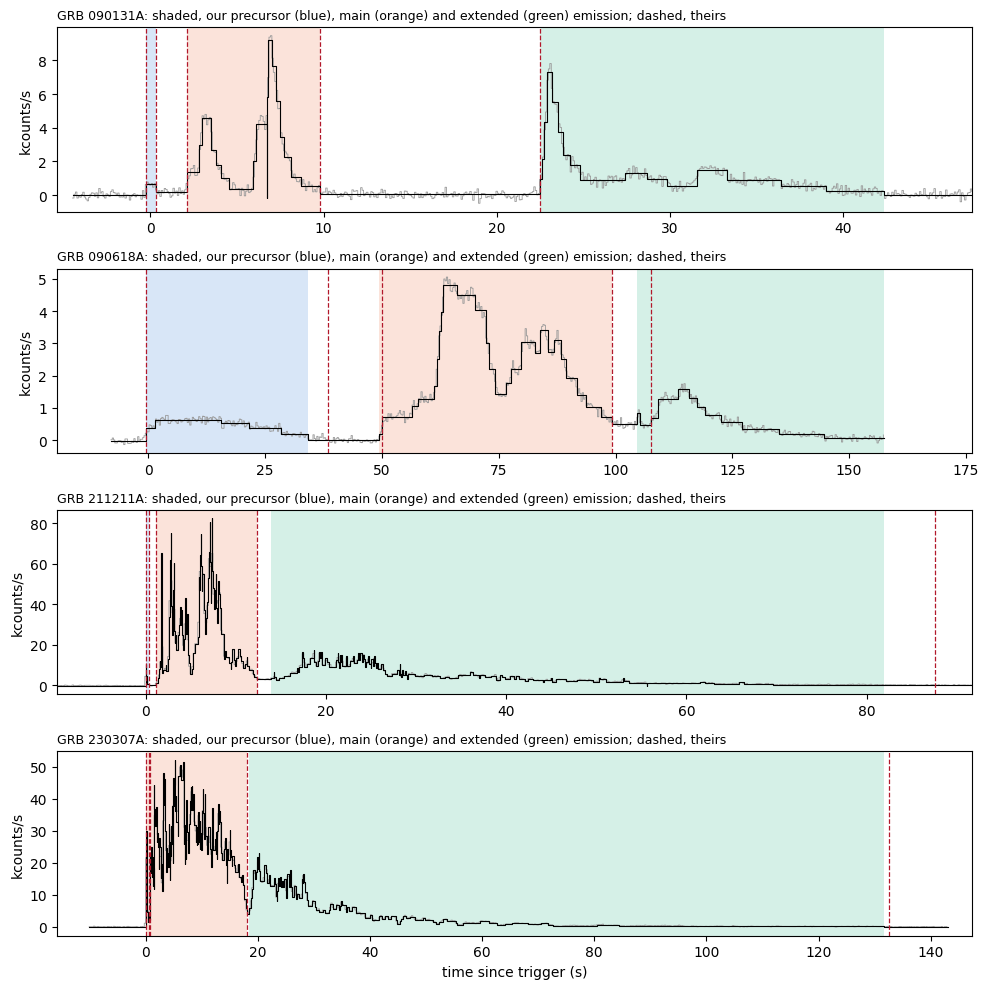

In [4]:
def their_edges(name, record):
    if name in BOUNDARIES_2025:
        b = BOUNDARIES_2025[name]
        return [b["PE"][0], b["PE"][1], b["ME"][0], b["ME"][1], b["EE"][0], b["EE"][1]]
    row = table.loc[name]
    start = record["pe"][0] if record.get("pe") else record["me"][0]
    return [start, start + row.T100_PE, start + row.T100_PE + row.T100_QE1, start + row.T100_PE + row.T100_QE1 + row.T100_ME, start + row.T100_WE]

fig, axes = plt.subplots(4, 1, figsize=(10, 10))
for ax, name in zip(axes, ["090131A", "090618A", "211211A", "230307A"]):
    folder = RESULTS / name
    record = json.loads((folder / "episodes.json").read_text())["modes"]["zhu2026"]
    lc, blocks = load_light_curve(folder)
    we = record["we"]
    pad = 0.12 * (we[1] - we[0])
    keep = np.flatnonzero((lc.edges[:-1] >= we[0] - pad) & (lc.edges[:-1] < we[1] + pad))
    factor = max(1, len(keep) // 600)
    starts = keep[::factor]
    net = np.add.reduceat((lc.counts - lc.background)[keep[0]:keep[-1] + 1], starts - keep[0])
    widths = np.diff(np.r_[lc.edges[starts], lc.edges[keep[-1] + 1]])
    ax.step(lc.edges[starts], net / widths / 1e3, where="post", color="0.6", lw=0.6)
    inside = blocks[(blocks.stop > we[0] - pad) & (blocks.start < we[1] + pad)]
    ax.step(np.r_[inside.start, inside.stop.values[-1]], np.r_[inside.rate, inside.rate.values[-1]] / 1e3, where="post", color="k", lw=0.8)
    for key, colour in (("pe", "#2a78d6"), ("me", "#eb6834"), ("ee", "#1baf7a")):
        if record.get(key):
            ax.axvspan(*record[key], color=colour, alpha=0.18, lw=0)
    for x in their_edges(name, record):
        ax.axvline(x, color="#b2182b", lw=0.9, ls="--")
    ax.set_xlim(we[0] - pad, we[1] + pad)
    ax.set_ylabel("kcounts/s")
    ax.set_title(f"GRB {name}: shaded, our precursor (blue), main (orange) and extended (green) emission; dashed, theirs", fontsize=9, loc="left")
axes[-1].set_xlabel("time since trigger (s)")
fig.tight_layout()
fig.savefig(FIGURES / "23_four_bursts.png", dpi=140)
plt.show()

## 3. Automatic comparison with their tables

Three tables, made the same way for every mode: the start and end of each episode where they print them (2025 Table 2), our durations against their 2026 Table 1 for every burst, and the 2025 text values of their six long-merger candidates.

In [5]:
rows = []
for name in BOUNDARIES_2025:
    episodes = json.loads((RESULTS / name / "episodes.json").read_text())["modes"]
    for mode in MODES:
        for episode in ("PE", "ME", "EE"):
            ours_span = episodes[mode].get(episode.lower())
            theirs = BOUNDARIES_2025[name][episode]
            rows.append(dict(burst=name, mode=mode, episode=episode, their_start=theirs[0], their_stop=theirs[1],
                             our_start=ours_span[0] if ours_span else np.nan, our_stop=ours_span[1] if ours_span else np.nan))
edges = pd.DataFrame(rows)
edges["start_diff_s"] = edges.our_start - edges.their_start
edges["stop_diff_s"] = edges.our_stop - edges.their_stop
print(edges.round(3).to_string(index=False))

  burst    mode episode  their_start  their_stop  our_start  our_stop  start_diff_s  stop_diff_s
090131A zhu2025      PE       -0.276       0.316     -0.276     0.316         0.000        0.000
090131A zhu2025      ME        2.096       9.780      2.096     9.780         0.000        0.000
090131A zhu2025      EE       22.476      84.040     22.476    42.348         0.000      -41.692
090131A zhu2026      PE       -0.276       0.316     -0.276     0.316         0.000        0.000
090131A zhu2026      ME        2.096       9.780      2.096     9.780         0.000        0.000
090131A zhu2026      EE       22.476      84.040     22.476    42.348         0.000      -41.692
090131A project      PE       -0.276       0.316     -0.276     0.316         0.000        0.000
090131A project      ME        2.096       9.780      2.096     9.780         0.000        0.000
090131A project      EE       22.476      84.040     22.476    42.348         0.000      -41.692
090618A zhu2025      PE       

In [6]:
rows = []
for mode, d in by_mode.items():
    theirs = table.loc[d.index]
    for q in TIMES:
        diff = np.log10(d[q] / theirs[q]).dropna()
        inside = ((theirs[q] >= d[f"{q}_p16"]) & (theirs[q] <= d[f"{q}_p84"]))[diff.index]
        rows.append(dict(number=q, mode=mode, bursts=len(diff), median_dex=diff.median(), within_0_05_dex=np.mean(np.abs(diff) < 0.05),
                         within_0_2_dex=np.mean(np.abs(diff) < 0.2), beyond_0_5_dex=np.mean(np.abs(diff) > 0.5), theirs_inside_our_68=inside.mean()))
durations = pd.DataFrame(rows).set_index(["number", "mode"]).sort_index()
durations.round(2)

bursts  median_dex  within_0_05_dex  within_0_2_dex  beyond_0_5_dex  theirs_inside_our_68
number   mode                                                                                              
T100_ME  project     110        0.01             0.38            0.65            0.17                  0.38
         zhu2025     110        0.00             0.43            0.67            0.16                  0.36
         zhu2026     110        0.00             0.49            0.72            0.13                  0.38
T100_PE  project      73       -0.00             0.58            0.75            0.08                  0.42
         zhu2025      89        0.00             0.55            0.75            0.11                  0.39
         zhu2026      96        0.00             0.59            0.78            0.09                  0.43
T100_QE1 project      73        0.00             0.67            0.90            0.05                  0.38
         zhu2025      89        0.00             0.64            0.92            0.04                  0.39
         zhu2026      96        0.00             0.66            0.90            0.06                  0.40
T100_WE  project     110        0.00             0.59            0.83            0.06                  0.42
         zhu2025     110        0.00             0.59            0.83            0.06                  0.42
         zhu2026     110        0.00             0.59            0.83            0.06                  0.42
TMVT_ME  project     110        0.03             0.08            0.30            0.43                  0.28
         zhu2025     110        0.00             0.27            0.47            0.29                  0.67
         zhu2026     110        0.02             0.30            0.48            0.29                  0.68
TMVT_PE  project      73        0.07             0.16            0.42            0.27                  0.18
         zhu2025      89        0.01             0.24            0.49            0.29                  0.69
         zhu2026      96        0.00             0.27            0.52            0.27                  0.70

In [7]:
rows = []
d = by_mode["zhu2025"]
for name, values in TEXT_2025.items():
    if name not in d.index:
        continue
    r = d.loc[name]
    for q, ours_q in (("T100_PE", "T100_PE"), ("T100_ME", "T100_ME"), ("T100_EE", "T100_EE"), ("T100_WE", "T100_WE"), ("T_wt1", "T100_QE1"),
                      ("TMVT_PE", "TMVT_PE"), ("TMVT_ME", "TMVT_ME")):
        if q in values:
            rows.append(dict(burst=name, number=q, theirs_2025_text=values[q], ours_zhu2025=r[ours_q]))
candidates = pd.DataFrame(rows)
candidates["dex"] = np.log10(candidates.ours_zhu2025 / candidates.theirs_2025_text)
print("within 0.1 dex:", round(float(np.mean(np.abs(candidates.dex.dropna()) < 0.1)), 2), "of", int(candidates.dex.notna().sum()))
candidates.round(3)

within 0.1 dex: 0.59 of 37


,burst,number,theirs_2025_text,ours_zhu2025,dex
0,090831A,T100_PE,0.030,0.032,0.028
1,090831A,T100_ME,0.280,0.276,-0.006
2,090831A,T100_EE,76.280,66.000,-0.063
3,090831A,T100_WE,80.000,69.720,-0.060
4,090831A,T_wt1,0.240,0.240,0.000
5,090831A,TMVT_ME,0.062,0.062,0.000
6,170228A,T100_PE,0.320,0.704,0.342
7,170228A,T100_ME,28.510,7.776,-0.564
8,170228A,T100_EE,81.180,57.952,-0.146
9,170228A,T100_WE,111.870,69.504,-0.207


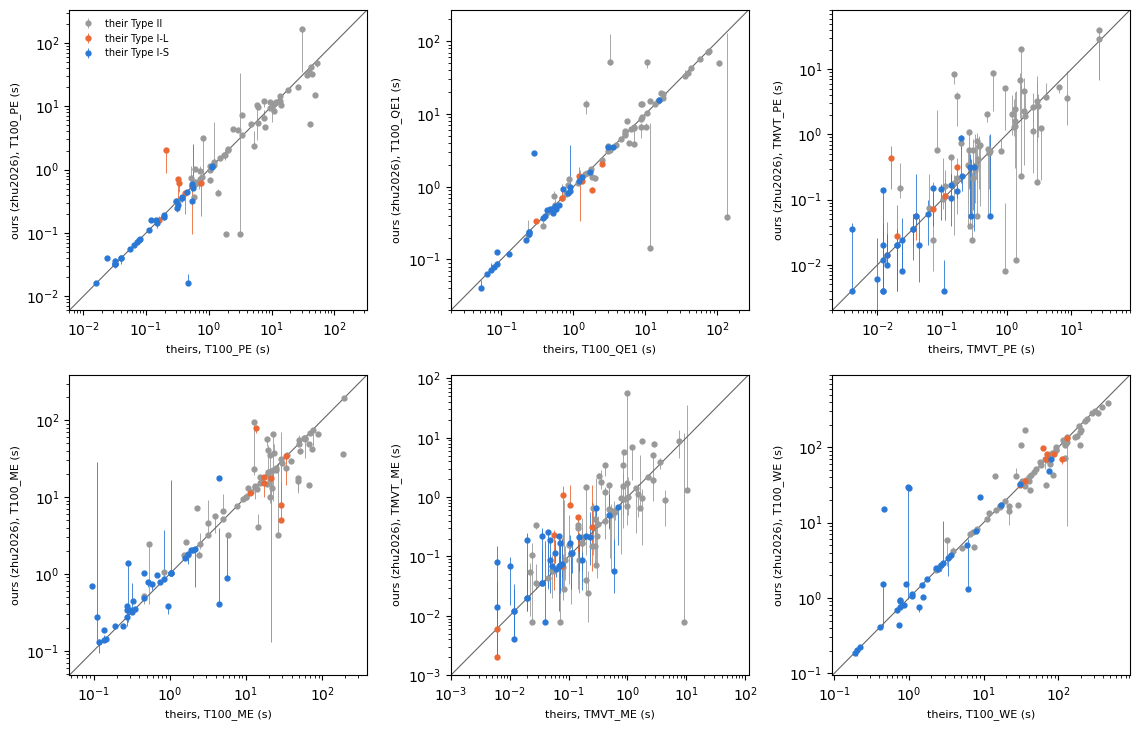

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(11.5, 7.4))
for ax, q in zip(axes.ravel(), TIMES):
    theirs = table.loc[ours.index, q]
    value = ours[q]
    lo = (value - ours[f"{q}_p16"]).clip(lower=0).fillna(0)
    hi = (ours[f"{q}_p84"] - value).clip(lower=0).fillna(0)
    for kind in ("II", "I-L", "I-S"):
        sel = (table.loc[ours.index, "Type"] == kind).values & value.notna().values
        ax.errorbar(theirs[sel], value[sel], yerr=[lo[sel], hi[sel]], fmt="o", ms=3.5, color=COLOURS[kind], elinewidth=0.6, capsize=0, label=f"their Type {kind}")
    good = pd.concat([theirs, value]).dropna()
    lim = [0.5 * good[good > 0].min(), 2 * good.max()]
    ax.plot(lim, lim, color="0.4", lw=0.8)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel(f"theirs, {q} (s)", fontsize=8); ax.set_ylabel(f"ours (zhu2026), {q} (s)", fontsize=8)
axes[0, 0].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(FIGURES / "23_ours_against_theirs.png", dpi=140)
plt.show()

GRB 090131's precursor and main emission are their printed edges to the millisecond under all three rules; its extended emission starts
where theirs does but ends at 42 s instead of 84 s, where a faint tail fades into the background. GRB 090618's precursor starts where
theirs does and ends 4.4 s earlier, and its main emission ends exactly where theirs does. Of the 96 bursts in which the zhu2026 rule finds a
precursor, T100,PE is theirs within 0.05 dex for 59% and within 0.2 dex for 78%, and T100,QE1 for 66% and 90%; over all 110, T100,ME is
within 0.05 and 0.2 dex for 49% and 72%. The main emission
agrees least because where it ends depends on how the extended emission is split off a faint tail. T_MVT agrees to 0.2 dex for only about
half the bursts, for the reason section 5 explains.

## 3b. What the changes of 13 November did

Three places where the code read their rules differently from them were found by comparing the first 81 bursts with their table: their T_MVT is the rise of the shortest pulse to its brightest bin, a precursor may peak above the main emission when the gap after it is at the background, and a short precursor long before the burst could sit inside the background interval. The same bursts under the old and the new rules:


In [9]:
OLD = RESULTS.parent / "zhu_12Nov_rules"          # the batch under the rules of 12 Nov, kept for this comparison


def agreement(t, common):
    t = t.loc[common]
    pe = np.log10(t.T100_PE / table.loc[common, "T100_PE"])
    qe = np.log10(t.T100_QE1 / table.loc[common, "T100_QE1"])
    mvt = np.abs(t.TMVT_PE - table.loc[common, "TMVT_PE"]) / table.loc[common, "Tres"]
    return pd.Series({"bursts": len(common), "precursor found": int(t.T100_PE.notna().sum()),
                      "T100,PE and T100,QE1 within 0.05 dex": int(((pe.abs() < 0.05) & (qe.abs() < 0.05)).sum()),
                      "T100,PE within 0.2 dex": int((pe.abs() < 0.2).sum()), "T_MVT,PE to the half-bin": int((mvt < 0.25).sum())})


if OLD.exists():
    before = collect("zhu2026", root=OLD)
    before = before[before.status == "complete"]
    now = ours[ours.status == "complete"]
    common = before.index.intersection(now.index)
    display(pd.DataFrame({"12 Nov rules": agreement(before, common), "13 Nov rules": agreement(now, common)}))
    had, has_now = before.loc[common].T100_PE.notna(), now.loc[common].T100_PE.notna()
    print("precursors found only under the 13 Nov rules:", ", ".join(common[has_now & ~had]) or "none")
    print("precursors found only under the 12 Nov rules:", ", ".join(common[had & ~has_now]) or "none")
else:
    print("results/zhu_12Nov_rules isn't here (it isn't part of the repository), so this comparison is skipped")


,12 Nov rules,13 Nov rules
bursts,110,110
precursor found,86,96
"T100,PE and T100,QE1 within 0.05 dex",47,51
"T100,PE within 0.2 dex",68,75
"T_MVT,PE to the half-bin",5,20


precursors found only under the 13 Nov rules: 090602A, 100223A, 120504B, 131209B, 131216A, 140304B, 151222A, 170412B, 190905A, 240513A
precursors found only under the 12 Nov rules: none


On the 110 bursts both batches finished, the rules of 13 November find 96 precursors against 86 (ten more, and none lost), reproduce
T100,PE and T100,QE1 together within 0.05 dex for 51 bursts against 47, and T_MVT,PE to the half-bin for 20 against 5. Each change was made from their own words and
table, not tuned to agree: the reading of T_MVT, the bright precursor, and the early-precursor scan.


## 4. Which quiet gap follows the precursor

When there are several quiet dips before the main peak, their words don't say which one ends the precursor; the zhu modes take the longest. Here the zhu2026 rule is rerun on every burst's saved blocks with the nearest, the first and the longest, and each is compared with their T100,PE and T100,QE1.

In [10]:
rows = []
for name in ours.index:
    lc, blocks = load_light_curve(RESULTS / name)
    for choice in ("nearest", "first", "longest"):
        found = find_episodes(lc, blocks, mode="zhu2026", qe1_choice=choice)
        d = found.durations()
        rows.append(dict(burst=name, choice=choice, several="quiet_gaps_before_main" in " ".join(found.flags),
                         PE_dex=np.log10(d["T100_PE"] / table.T100_PE[name]), QE1_dex=np.log10(d["T100_QE1"] / table.T100_QE1[name])))
choices = pd.DataFrame(rows)
summary = lambda g: pd.Series(dict(bursts=len(g), with_precursor=int(g.PE_dex.notna().sum()), PE_within_0_2=np.mean(np.abs(g.PE_dex.dropna()) < 0.2), QE1_within_0_2=np.mean(np.abs(g.QE1_dex.dropna()) < 0.2)))
print("all bursts:"); print(choices.groupby("choice").apply(summary).round(2).to_string())
print("bursts with several quiet dips:"); print(choices[choices.several].groupby("choice").apply(summary).round(2).to_string())

all bursts:
         bursts  with_precursor  PE_within_0_2  QE1_within_0_2
choice                                                        
first     110.0            96.0           0.72            0.83
longest   110.0            96.0           0.78            0.90
nearest   110.0            96.0           0.69            0.78
bursts with several quiet dips:
         bursts  with_precursor  PE_within_0_2  QE1_within_0_2
choice                                                        
first      27.0            26.0           0.42            0.54
longest    27.0            26.0           0.65            0.77
nearest    27.0            26.0           0.31            0.35


Taking the longest quiet dip before the main peak matches them best: of the bursts where a precursor is found, their T100,QE1 comes back
within 0.2 dex for 90%, and for 77% of those with several dips, against 54% for the first dip and 35% for the nearest. So when several quiet stretches precede the main
emission, they took the longest as the gap.

## 5. What their MVT is

Both papers define T_MVT as the rise time of the shortest pulse that Bayesian blocks pick out, citing Xiao et al. (2023), who measure it as half the shortest block whose edges are certain at 5 sigma. Four readings are compared with their values, on bursts where our window has the same duration as theirs within 0.05 dex: certain (used here), shortest (half the shortest block, no test), rise (from the start of the shortest pulse to its peak block) and half_width (half the run of blocks above half a pulse's peak).

In [11]:
# their own table: every T_MVT in units of their time bin
for ep in ("PE", "ME"):
    hb = 2 * table[f"TMVT_{ep}"] / table.Tres                    # T_MVT in half-bins
    whole = np.isclose(hb, hb.round(), atol=1e-6)
    half_episode = np.isclose(hb, table[f"T100_{ep}"] / table.Tres, atol=1e-6)
    print(f"T_MVT,{ep}: a whole number of half-bins {whole.mean():.2f}, an odd number {np.mean(hb.round() % 2 == 1):.2f}, "
          f"exactly half the episode {half_episode.mean():.2f}")
hb = 2 * table.TMVT_PE / table.Tres
half_pe = np.isclose(hb, table.T100_PE / table.Tres, atol=1e-6)
u = (table.TMVT_PE - table.Tres / 2) / table.T100_PE              # where the bin it points to sits in the precursor
print(f"the other T_MVT,PE: in the first half of the precursor {np.mean(u[~half_pe] < 0.5):.2f}, in the first quarter {np.mean(u[~half_pe] < 0.25):.2f}")
odd_rest = np.mean(hb.round()[~half_pe] % 2 == 1)
print(f"T_MVT,PE that are not half the precursor: an odd number of half-bins {odd_rest:.2f}")
# which of their precursors got half the precursor: the number of our blocks inside the same burst's precursor
half_series = pd.Series(half_pe, index=table.index)
rows = []
for name in ours.index[ours.T100_PE.notna()]:
    pe = json.loads((RESULTS / name / "episodes.json").read_text())["modes"]["zhu2026"]["pe"]
    _, blocks = load_light_curve(RESULTS / name)
    inside = (blocks.start >= pe[0] - 1e-6) & (blocks.stop <= pe[1] + 1e-6)
    rows.append(dict(name=name, one_block=int(inside.sum()) == 1, their_half=bool(half_series.get(name, False))))
blocks_vs_half = pd.DataFrame(rows).set_index("name")
print(pd.crosstab(blocks_vs_half.one_block, blocks_vs_half.their_half, rownames=["our precursor is one block"],
                  colnames=["their T_MVT,PE is half the precursor"]))


T_MVT,PE: a whole number of half-bins 1.00, an odd number 0.84, exactly half the episode 0.27
T_MVT,ME: a whole number of half-bins 1.00, an odd number 0.96, exactly half the episode 0.01
the other T_MVT,PE: in the first half of the precursor 0.80, in the first quarter 0.56
T_MVT,PE that are not half the precursor: an odd number of half-bins 0.94


their T_MVT,PE is half the precursor  False  True 
our precursor is one block                        
False                                    42      2
True                                     31     21


In [12]:
rows = []
for ep in ("PE", "ME"):
    same = np.abs(np.log10(ours[f"T100_{ep}"] / table.loc[ours.index, f"T100_{ep}"])) < 0.05
    names = same[same].index
    for reading in ("brightest", "certain", "shortest", "rise", "half_width"):
        column = f"TMVT_{ep}_{reading}"
        if column not in ours:
            continue
        d = np.log10(ours.loc[names, column].astype(float) / table.loc[names, f"TMVT_{ep}"]).dropna()
        gap = np.abs(ours.loc[d.index, column].astype(float) - table.loc[d.index, f"TMVT_{ep}"]) / table.loc[d.index, "Tres"]
        rows.append(dict(episode=ep, reading=reading, bursts=len(d), median_dex=d.median(), scatter_dex=d.std(), same_half_bin=np.mean(gap < 0.25), within_0_1_dex=np.mean(np.abs(d) < 0.1),
                         within_0_3_dex=np.mean(np.abs(d) < 0.3)))
pd.DataFrame(rows).set_index(["episode", "reading"]).round(2)

bursts  median_dex  scatter_dex  same_half_bin  within_0_1_dex  within_0_3_dex
episode reading                                                                                   
PE      brightest       57        0.00         0.47           0.30            0.47            0.63
        certain         26       -0.00         0.52           0.08            0.31            0.62
        shortest        57       -0.00         0.45           0.12            0.32            0.65
        rise            57        0.05         0.38           0.11            0.37            0.75
        half_width      57        0.00         0.40           0.12            0.39            0.70
ME      brightest       54        0.00         0.42           0.24            0.41            0.57
        certain         43       -0.09         0.60           0.02            0.19            0.58
        shortest        54       -0.41         0.65           0.02            0.11            0.37
        rise            54        0.12         0.34           0.02            0.26            0.63
        half_width      54        0.23         0.48           0.04            0.13            0.46

In [13]:
# inside one Bayesian block the brightest bin is wherever the counting noise puts it: T_MVT = u T100 with u uniform on (0, 1),
# so log10 T_MVT carries -log10(u), mean and spread 1/ln10 = 0.43 dex. The realisations show the same burst by burst.
spread = 0.5 * (np.log10(ours.TMVT_PE_p84) - np.log10(ours.TMVT_PE_p16))
print(f"T_MVT,PE spread over the realisations (half the 16-84% range in dex): median {spread.median():.2f} over {spread.notna().sum()} bursts")
rng = np.random.default_rng(1)
k = np.argmax(rng.poisson(20, (100000, 20)) + 1e-6 * rng.random((100000, 20)), axis=1)
x = -np.log10((k + 0.5) / 20)
print(f"simulated one-block precursor of 20 bins: -log10(T_MVT/T100,PE) mean {x.mean():.2f} dex, spread {x.std():.2f} dex")


T_MVT,PE spread over the realisations (half the 16-84% range in dex): median 0.33 over 103 bursts
simulated one-block precursor of 20 bins: -log10(T_MVT/T100,PE) mean 0.43 dex, spread 0.40 dex


Their table shows how they read T_MVT. Every T_MVT,PE and T_MVT,ME is a whole number of half-bins. 27% of the T_MVT,PE are exactly
half the precursor, and in our sample those are almost all precursors that our blocks make a single block (21 of 23): for those they took
half the block. The rest are nearly all odd numbers of half-bins (94%), which is what the time from a block edge to the centre of a bin
gives: the rise of the shortest pulse to the centre of its brightest bin. That reading, applied to every burst, gives their value to the
half-bin for 30% of the precursors and within 0.1 dex for 47%; the other readings (certain edges, shortest block, rise to the peak block,
half-width) do worse. Their table mixes the two, and not by a rule we can see: 31 other one-block precursors don't get half the block.

Inside a precursor that is a single block, the brightest bin is wherever counting noise puts it: a simulated one-block precursor gives
-log10(T_MVT/T100,PE) a mean of 0.43 dex and a spread of 0.40, as a uniform position predicts (1/ln 10), and our 40 simulated light
curves move T_MVT,PE by a median 0.33 dex. So T_MVT,PE read as the brightest bin carries about 0.4 dex of counting noise in a one-block
precursor. That is in our values, and so in our EPI, and in theirs wherever they read the brightest bin; where they took half the
precursor it is a fixed number, so part of the scatter between ours and theirs is the difference between the two readings.

## 6. Does the choice of detectors matter

Xiao et al. use every detector within 60 degrees; this project uses the GBM catalogue's NaIs. For six bursts the zhu2026 rule was run both ways (`features.detector_test`, saved because it reads the photons again).

In [14]:
detectors = pd.read_csv(RESULTS / "calibration" / "detectors.csv")
for q in TIMES:
    detectors[f"their_{q}"] = table.loc[detectors.GRB, q].values
detectors.set_index(["GRB", "detectors"])[["which"] + [c for q in TIMES for c in (q, f"their_{q}")]].round(3)

which  T100_PE  their_T100_PE  T100_QE1  their_T100_QE1  TMVT_PE  their_TMVT_PE  T100_ME  their_T100_ME  TMVT_ME  their_TMVT_ME  T100_WE  their_T100_WE
GRB     detectors                                                                                                                                                                      
090131A catalogue               n9 na    0.592          0.592     1.780           1.780    0.102          0.102    7.684          7.684    0.710          0.974   42.624         84.316
        within 60 deg     n9 n0 na n6    0.560          0.592     1.812           1.780    0.026          0.102    7.684          7.684    1.242          0.974   43.832         84.316
160509A catalogue            n0 n1 n3    5.208         40.200     3.128           3.064    1.276          3.404   36.664        185.752    0.556          0.612  385.728        457.824
        within 60 deg  n3 n0 n1 n6 n5    4.904         40.200     3.304           3.064    3.276          3.404   42.176        185.752    0.556          0.612  385.088        457.824
180605A catalogue            n0 n1 n2    0.016          0.472     2.912           0.288    0.004          0.108    1.032          0.464    0.220          0.068   32.296         30.432
        within 60 deg  n1 n2 n0 n9 na    0.016          0.472     2.912           0.288    0.004          0.108    1.032          0.464    0.244          0.068   32.296         30.432
200101A catalogue            n5 n1 n0   12.312         13.472     1.480           1.476    0.150          0.022   15.256         15.204    0.066          0.082  102.432         92.204
        within 60 deg  n5 n1 n0 n3 n2   12.484         13.472     1.592           1.476    0.098          0.022   15.448         15.204    0.078          0.082   91.336         92.204
200311A catalogue               n8 n4    2.032          0.208     0.336           0.304    0.072          0.072   15.280         17.136    0.232          0.056   69.184         69.216
        within 60 deg           n8 n4    2.032          0.208     0.336           0.304    0.072          0.072   15.280         17.136    0.232          0.056   69.184         69.216
211211A catalogue               n2 na    0.424          0.424     0.692           0.692    0.014          0.014   11.236         11.236    0.002          0.006   81.912         87.564
        within 60 deg           n2 na    0.424          0.424     0.692           0.692    0.014          0.014   11.236         11.236    0.002          0.006   81.912         87.564

For the six bursts tried both ways, using every NaI within 60 degrees (Xiao et al.'s choice) instead of the catalogue's changes the
precursor and the gap by about 0.03 dex at most: GRB 211211A and 200311A use the same detectors either way, and 090131A, 160509A and
200101A move by 0.01-0.03 dex. Only T_MVT moves a lot (090131A: 0.102 s with the catalogue's NaIs, as theirs, against 0.026 s), again
because it is a single brightest bin. The catalogue's choice gives their numbers exactly for GRB 090131A and 211211A, so it stays.

## 7. How large the errors are

The half-width of the 68% interval over the 40 simulated light curves as a fraction of the value, how often the precursor is found at all, and how often each number moves by more than 0.1 dex at half and twice their Tres.

In [15]:
rows = []
for mode, d in by_mode.items():
    for q in TIMES:
        width = ((d[f"{q}_p84"] - d[f"{q}_p16"]) / 2 / d[q]).dropna()
        half = np.log10(d[f"{q}_half"] / d[q]).dropna() if f"{q}_half" in d else pd.Series(dtype=float)
        double = np.log10(d[f"{q}_double"] / d[q]).dropna() if f"{q}_double" in d else pd.Series(dtype=float)
        rows.append(dict(number=q, mode=mode, median_fractional_error=width.median(), share_over_30_percent=np.mean(width > 0.3),
                         half_tres_moved_0_1_dex=np.mean(np.abs(half) > 0.1), twice_tres_moved_0_1_dex=np.mean(np.abs(double) > 0.1)))
    print(f"{mode}: precursor found in every simulation for {np.mean(d.pe_found_fraction == 1.0):.2f} of bursts, in under 80% for {int(np.sum(d.pe_found_fraction < 0.8))}")
pd.DataFrame(rows).set_index(["number", "mode"]).sort_index().round(2)

zhu2025: precursor found in every simulation for 0.49 of bursts, in under 80% for 27
zhu2026: precursor found in every simulation for 0.53 of bursts, in under 80% for 18
project: precursor found in every simulation for 0.33 of bursts, in under 80% for 52


median_fractional_error  share_over_30_percent  half_tres_moved_0_1_dex  twice_tres_moved_0_1_dex
number   mode                                                                                                      
T100_ME  project                     0.05                   0.22                     0.12                      0.20
         zhu2025                     0.07                   0.23                     0.18                      0.21
         zhu2026                     0.05                   0.18                     0.11                      0.23
T100_PE  project                     0.04                   0.12                     0.07                      0.11
         zhu2025                     0.05                   0.12                     0.10                      0.11
         zhu2026                     0.06                   0.12                     0.09                      0.12
T100_QE1 project                     0.02                   0.03                     0.04                      0.03
         zhu2025                     0.03                   0.08                     0.05                      0.06
         zhu2026                     0.03                   0.07                     0.04                      0.06
T100_WE  project                     0.01                   0.05                     0.03                      0.02
         zhu2025                     0.01                   0.05                     0.03                      0.02
         zhu2026                     0.01                   0.05                     0.03                      0.02
TMVT_ME  project                     0.27                   0.48                     0.27                      0.32
         zhu2025                     0.53                   0.77                     0.49                      0.49
         zhu2026                     0.55                   0.78                     0.48                      0.49
TMVT_PE  project                     0.07                   0.18                     0.13                      0.17
         zhu2025                     0.71                   0.87                     0.57                      0.56
         zhu2026                     0.64                   0.84                     0.55                      0.52

The durations are well measured: the median 68% half-width is 6% for T100,PE, 3% for T100,QE1 and 5% for T100,ME, and halving or doubling
the time bin moves T100,PE by more than 0.1 dex for only 9-12% of bursts. T_MVT is not: its half-width is about 65% for the precursor, and
the bin moves it by more than 0.1 dex for about half the bursts. The precursor itself is found in every simulation for 53% of bursts and
in under 80% of them for 18: those precursors are close to the rule's thresholds.

## 8. Every significant disagreement, and why

Every burst where our zhu2026 T100,PE or T100,QE1 differs from theirs by more than 0.3 dex (a factor of 2), or where we find no precursor. The likely cause is sorted from what the rule recorded and from the saved blocks:

- no precursor: no long dip before the main peak is below 3 sigma per bin (the closest miss is given);
- other gap: their QE1 matches one of our other long quiet dips before the main emission to within 20%, so the rule picked a different gap;
- same gap, other start: our QE1 matches theirs to within 20% but the precursor doesn't, so the precursor starts elsewhere;
- edge: an excess at the start of the light curve was ignored, or emission runs into the background interval;
- other: none of these.

In [16]:
from zhu.features import boundary_cause

pe_dex = np.log10(ours.T100_PE / table.loc[ours.index, "T100_PE"])
qe_dex = np.log10(ours.T100_QE1 / table.loc[ours.index, "T100_QE1"])
far = ours[(pe_dex.abs() > 0.3) | (qe_dex.abs() > 0.3) | ours.T100_PE.isna()].copy()
far["Type"] = table.loc[far.index, "Type"]
far["their_PE"], far["their_QE1"] = table.loc[far.index, "T100_PE"], table.loc[far.index, "T100_QE1"]
far["cause"] = [boundary_cause(name, r, table) for name, r in far.iterrows()]
print(len(far), "of", len(ours), "bursts disagree by more than 0.3 dex in T100,PE or T100,QE1, or have no precursor")
print(far.cause.str.split(" [(]").str[0].value_counts().to_string())
far[["Type", "their_PE", "T100_PE", "their_QE1", "T100_QE1", "pe_found_fraction", "cause", "flags"]].round(3)

29 of 110 bursts disagree by more than 0.3 dex in T100,PE or T100,QE1, or have no precursor
cause
no precursor             14
other                     6
other gap                 5
same gap, other start     4


,Type,their_PE,T100_PE,their_QE1,T100_QE1,pe_found_fraction,cause,flags
name,,,,,,,,
090828A,II,49.248,14.912,1.504,13.920,1.000,other,quiet_gaps_before_main:2 emission_close_to_start_of_data
090907B,I-S,0.176,NaN,0.120,NaN,0.000,no precursor,no_quiet_gap_before_main
110825A,II,0.808,3.200,7.056,3.880,1.000,other,quiet_gaps_before_main:2 emission_close_to_start_of_data
110903B,II,3.088,0.096,3.248,52.400,1.000,other,quiet_gaps_before_main:4 emission_close_to_start_of_data
111117A,I-S,0.216,NaN,0.192,NaN,0.100,no precursor,excess_at_start_ignored pe_counts_not_below_me
130206B,II,1.872,0.096,10.480,52.016,1.000,other gap,quiet_gaps_before_main:2 ep_error_one_sided:PE_ours
131216A,II,0.512,0.736,106.560,49.664,0.750,other,emission_close_to_start_of_data ep_error_one_sided:PE_zhu ep_error_one_sided:PE_ours
131217B,II,6.336,NaN,2.000,NaN,0.200,no precursor,no_quiet_gap_before_main
140304B,II,30.624,165.696,134.944,0.384,0.950,other gap,pe_peak_above_me_peak background_poor_fit ep_error_one_sided:PE_zhu ep_error_one_sided...


### The threshold of a quiet episode

Both papers ask for a quiet episode with an SNR "below (around) 3 sigma", and Zhu et al. (2026) accept GRB 230307A's gap, which they state as 3.15 sigma, so their threshold isn't exactly 3. The rule is run again on every burst's saved light curve and blocks with the per-bin threshold (`QUIET_SIGMA`, 3 here) raised step by step, and each change is checked against their durations.


In [17]:
import zhu.episodes as E
saved = {n: load_light_curve(RESULTS / n) for n in ours.index if (RESULTS / n / "light_curve.npz").exists()}
base, rows = E.QUIET_SIGMA, []
for quiet in (3.0, 3.15, 3.3, 3.5, 4.0):
    E.QUIET_SIGMA = quiet
    for n, (lc, blocks) in saved.items():
        r = E.find_episodes(lc, blocks, mode="zhu2026", burst=n)
        dex = lambda w, q: np.log10((w[1] - w[0]) / table.loc[n, q]) if w else np.nan
        rows.append(dict(quiet_sigma=quiet, burst=n, has_pe=r.pe is not None, PE_dex=dex(r.pe, "T100_PE"), QE1_dex=dex(r.qe1, "T100_QE1")))
E.QUIET_SIGMA = base
scan = pd.DataFrame(rows)
print(scan.groupby("quiet_sigma").apply(lambda g: pd.Series(dict(
    precursor_found=int(g.has_pe.sum()), PE_and_QE1_within_0_05=int(((g.PE_dex.abs() < 0.05) & (g.QE1_dex.abs() < 0.05)).sum())))).to_string())
first = scan[scan.quiet_sigma == 3.0].set_index("burst")
for quiet in (3.15, 3.3, 3.5, 4.0):
    other = scan[scan.quiet_sigma == quiet].set_index("burst")
    moved = first.index[(first.has_pe != other.has_pe) | ((first.PE_dex - other.PE_dex).abs() > 1e-9) | ((first.QE1_dex - other.QE1_dex).abs() > 1e-9)]
    print(f"from 3 to {quiet}:", ", ".join(f"{n} (PE {other.PE_dex[n]:+.2f} dex, QE1 {other.QE1_dex[n]:+.2f} dex from theirs)" for n in moved) or "no burst changes")
if "230307A" in ours.index:
    print("GRB 230307A under the rule as written:", ours.loc["230307A", "flags"])


             precursor_found  PE_and_QE1_within_0_05
quiet_sigma                                         
3.00                      96                      51
3.15                      96                      51
3.30                      97                      51
3.50                      97                      51
4.00                      97                      51
from 3 to 3.15: no burst changes
from 3 to 3.3: 230307A (PE -0.16 dex, QE1 -0.54 dex from theirs)
from 3 to 3.5: 230307A (PE -0.16 dex, QE1 -0.54 dex from theirs)
from 3 to 4.0: 230307A (PE -0.16 dex, QE1 -0.54 dex from theirs)
GRB 230307A under the rule as written: no_quiet_gap_before_main nearest_miss_qe1_snr:3.26


29 of the 110 bursts differ from their T100,PE or T100,QE1 by more than a factor of 2 or have no precursor. 14 have no precursor under
the rule: no quiet gap at 3 sigma per bin before the main peak, or a precursor with more counts than the main emission. 4 have the same
gap with a different start, 5 another quiet dip, and 6 fit none of these causes. The threshold for a quiet episode isn't behind them: between 3 and 4
sigma only GRB 230307A changes, and then its gap is 0.54 dex shorter than theirs, so their gap sits on blocks cut differently from ours.
GRB 230307A therefore has no precursor under the rule as written; notebook 26 uses notebook 12's window for it, drawn apart.

## 9. What this says

Their bursts are measured again with their rules as code, and where the rules are clear the numbers come back: the precursor and the gap
within 0.2 dex for 78% and 90% of the 96 bursts with a precursor, GRB 090131A's edges and GRB 211211A's precursor, gap, main emission and
T_MVT,PE exactly. Most differences have causes that can be named: where a faint tail ends, which quiet dip is the gap, and above all
T_MVT, which read as the brightest bin is set by counting noise in a one-block precursor (0.4 dex), while for some of those precursors
they took half the precursor. That last point matters for what follows, because T_MVT,PE enters EPI with power one.